In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create sparse design matrix X with most entries zero
np.random.seed(42)
N, P = 100, 20  # 100 samples, 20 features

# Sparse matrix: 90% zeros
X_sparse = np.random.binomial(1, 0.1, size=(N, P)) * np.random.randn(N, P)

# True sparse coefficients
true_beta = np.zeros(P)
true_beta[[0, 4, 9]] = [2.0, -1.0, 1.5]

# Generate response with noise
y_sparse = X_sparse @ true_beta + np.random.randn(N) * 0.3
X_sparse.shape, y_sparse.shape

((100, 20), (100,))

In [2]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LassoCV

lasso_cv_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('lasso', LassoCV(cv=5))
])
lasso_cv_pipe.fit(X_sparse, y_sparse)
y_pred_lasso = lasso_cv_pipe.predict(X_sparse)
mse_lasso = mean_squared_error(y_sparse, y_pred_lasso)
r2_lasso = r2_score(y_sparse, y_pred_lasso)


coef_lasso = lasso_cv_pipe.named_steps['lasso'].coef_
zero_lasso = np.sum(np.abs(coef_lasso) < 1e-8)

# Adative Lasso regression pipeline
from jax_model_lib.jax_sklearn_adapter import MAPAdaptiveLasso
P = X_sparse.shape[1]  # = 20

def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        'log_gamma': np.zeros(G, dtype=float),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P].astype(float)
    }
pipe = Pipeline([
    ('scale', StandardScaler()),
    ('jax_model', MAPAdaptiveLasso(
    lam_prior='group',
    lik='normal',
    lam_prior_vars=get_group_vars(P),
#    invlam = True,
#     logprox = True,
    track = True
))
])

pipe.fit(X_sparse, y_sparse)
y_pred_jax = pipe.predict(X_sparse)
mse_jax = mean_squared_error(y_sparse, y_pred_jax)
r2_jax = r2_score(y_sparse, y_pred_jax)

coef_jax = pipe.named_steps['jax_model'].get_coefficients()
zero_jax = np.sum(np.abs(coef_jax) < 1e-8)




Non-finite or non-positive sigma2 in reset_vars: -0.6803902394436527


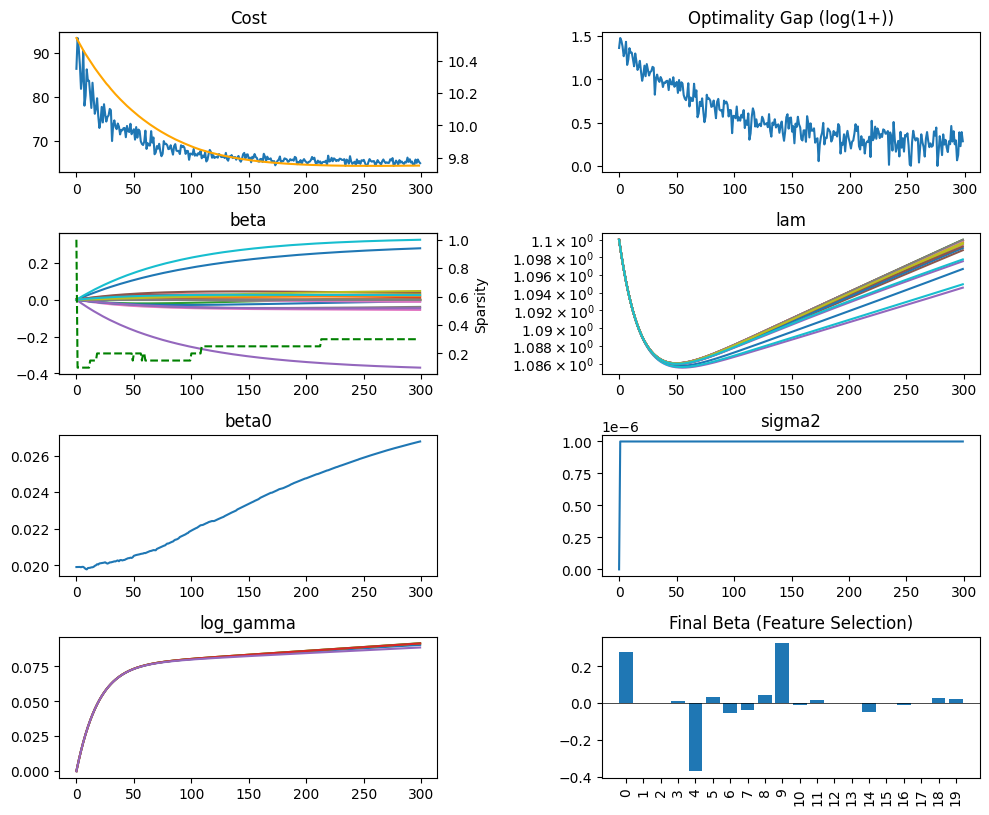

In [3]:
pipe.named_steps['jax_model'].model_.tracking.keys()
pipe.named_steps['jax_model'].model_.plot()

In [4]:
print(f"Lasso Regression     MSE: {mse_lasso:.4f}, R²: {r2_lasso:.4f}")
print(f"JAX Sparse Regressor MSE: {mse_jax:.4f}, R²: {r2_jax:.4f}")

print(f"Lasso shrank to 0:      {zero_lasso} / {len(coef_lasso)}")
print(f"JAX sparse shrank to 0: {zero_jax} / {len(coef_jax)}")

Lasso Regression     MSE: 0.0813, R²: 0.8316
JAX Sparse Regressor MSE: 0.0751, R²: 0.8443
Lasso shrank to 0:      13 / 20
JAX sparse shrank to 0: 6 / 20


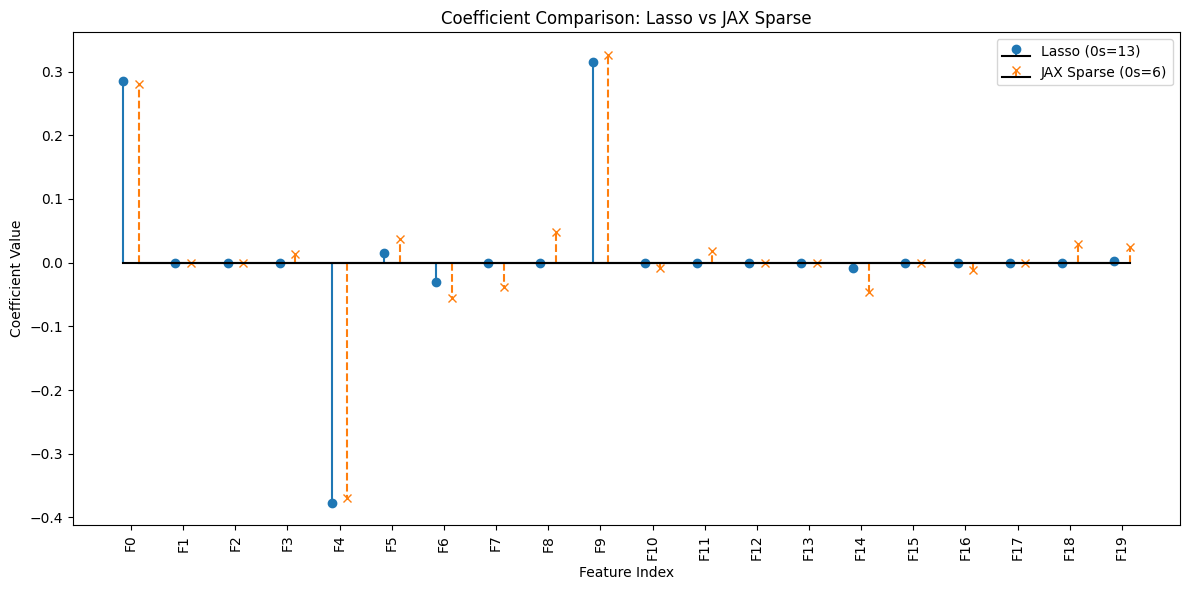

In [5]:
# Plot
x = np.arange(len(coef_lasso))
plt.figure(figsize=(12, 6))
plt.stem(x - 0.15, coef_lasso, linefmt='C0-', markerfmt='C0o', basefmt='k-', label=f'Lasso (0s={zero_lasso})')
plt.stem(x + 0.15, coef_jax, linefmt='C1--', markerfmt='C1x', basefmt='k-', label=f'JAX Sparse (0s={zero_jax})')
plt.xticks(x, [f"F{i}" for i in x], rotation=90)
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Comparison: Lasso vs JAX Sparse")
plt.legend()
plt.tight_layout()
plt.show()

# All test cases

In [6]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from jax_model_lib.jax_sklearn_adapter import MAPAdaptiveLasso
from sklearn.compose import TransformedTargetRegressor
import traceback

N, P = 100, 20
X = np.random.randn(N, P)

true_beta = np.zeros(P)
true_beta[:5] = [3.0, -2.0, 1.5, 0.5, -1.0]

y_normal = X @ true_beta + np.random.randn(N)
y_binary = (y_normal > np.median(y_normal))
y_poisson = np.random.poisson(lam=np.exp(np.clip(X[:, 0], 0, 3)))
y_nb = y_poisson + np.random.negative_binomial(1, 0.5, size=N)
y_zinb = y_poisson.copy()
y_zinb[np.random.rand(N) < 0.3] = 0
y_cauchy = np.clip(X @ true_beta + np.random.standard_cauchy(size=N), -10, 10) 

def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        #'log_gamma': np.zeros(G, dtype=float),
        'log_gamma': np.zeros(G),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P]
    }

cases = [
    {'lam_prior': 'adaptive', 'lik': 'normal'},
    {'lam_prior': 'adaptive', 'lik': 'poisson'},
    {'lam_prior': 'adaptive', 'lik': 'bernoulli'},
    {'lam_prior': 'adaptive', 'lik': 'nb'},
    {'lam_prior': 'adaptive', 'lik': 'zinb'},
    {'lam_prior': 'adaptive', 'lik': 'zinb', 'lam_prior_vars': {}},
    {'lam_prior': 'adaptive', 'lik': 'cauchy'},
    {'lam_prior': 'group', 'lik': 'normal', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'poisson', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'bernoulli', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'nb', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'zinb', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'cauchy', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'hier', 'lik': 'normal'},
    {'lam_prior': 'hier', 'lik': 'poisson'},
    {'lam_prior': 'hier', 'lik': 'bernoulli'},
]

lik2y = {
    'normal': y_normal,
    'poisson': y_poisson,
    'bernoulli': y_binary,
    'nb': y_nb,
    'zinb': y_zinb,
    'cauchy': y_cauchy
}

for i, case in enumerate(cases):
    try:
        y_target = lik2y[case['lik']]
        model = MAPAdaptiveLasso(
            **case
        )
        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('model', model)
        ])

        pipe.fit(X, y_target)
        y_pred = pipe.predict(X)
        coef = pipe.named_steps['model'].get_coefficients()
        r2 = r2_score(y_target, y_pred)
        nz = np.sum(np.abs(coef) > 1e-6)
        print(f"Case {i+1}: lik={case['lik']:8s}, prior={case['lam_prior']:7s}, R²={r2:.3f}, nonzero={nz}")
    except Exception as e:
        print(f"Case {i+1} failed: {e}")
        traceback.print_exc()


Case 1: lik=normal  , prior=adaptive, R²=0.575, nonzero=17
Case 2: lik=poisson , prior=adaptive, R²=0.500, nonzero=20
Case 3: lik=bernoulli, prior=adaptive, R²=0.376, nonzero=19
Case 4: lik=nb      , prior=adaptive, R²=0.312, nonzero=15
Case 5: lik=zinb    , prior=adaptive, R²=0.266, nonzero=31
Case 6: lik=zinb    , prior=adaptive, R²=0.264, nonzero=31
Case 7: lik=cauchy  , prior=adaptive, R²=0.195, nonzero=18
Case 8: lik=normal  , prior=group  , R²=0.571, nonzero=18
Case 9: lik=poisson , prior=group  , R²=0.484, nonzero=18
Case 10: lik=bernoulli, prior=group  , R²=0.372, nonzero=18
Case 11: lik=nb      , prior=group  , R²=0.298, nonzero=16
Case 12: lik=zinb    , prior=group  , R²=0.271, nonzero=29
Case 13: lik=cauchy  , prior=group  , R²=0.210, nonzero=20
Case 14: lik=normal  , prior=hier   , R²=0.572, nonzero=17
Case 15: lik=poisson , prior=hier   , R²=0.504, nonzero=19
Case 16: lik=bernoulli, prior=hier   , R²=0.360, nonzero=17


# Test our lasso without scaling

# Test cauchy

In [7]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score
from jax_model_lib.jax_sklearn_adapter import MAPAdaptiveLasso
import traceback

N, P = 100, 20
X = np.random.randn(N, P)

true_beta = np.zeros(P)
true_beta[:5] = [3.0, -2.0, 1.5, 0.5, -1.0]

y_cauchy = np.clip(X @ true_beta + np.random.standard_cauchy(size=N), -10, 10) 

def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        #'log_gamma': np.zeros(G, dtype=float),
        'log_gamma': np.zeros(G),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P]
    }

cases = [
    {'lam_prior': 'adaptive', 'lik': 'cauchy',},
    {'lam_prior': 'group', 'lik': 'cauchy', 'lam_prior_vars': get_group_vars(P)},

]

lik2y = {
    'cauchy': y_cauchy
}

for i, case in enumerate(cases):
    try:
        y_target = lik2y[case['lik']]
        model = MAPAdaptiveLasso(
            **case
        )
        pipe = Pipeline([
            ('scale', RobustScaler()),
            ('model', model),
        ])

        pipe.fit(X, y_target)
        y_pred = pipe.predict(X)
        coef = pipe.named_steps['model'].get_coefficients()
        r2 = r2_score(y_target, y_pred)
        nz = np.sum(np.abs(coef) > 1e-6)
        print(f"Case {i+1}: lik={case['lik']:8s}, prior={case['lam_prior']:7s}, R²={r2:.3f}, nonzero={nz}")
    except Exception as e:
        print(f"Case {i+1} failed: {e}")
        traceback.print_exc()


Case 1: lik=cauchy  , prior=adaptive, R²=0.118, nonzero=17
Case 2: lik=cauchy  , prior=group  , R²=0.116, nonzero=15


# Test Cauchy with custom_cauchy_nll_grad

In [8]:
import jax.numpy as jnp

def custom_cauchy_nll_grad(vv, Xb, yb):
    beta = vv['beta']
    beta0 = vv['beta0']
    sigma2 = vv['sigma2']
    preds = Xb @ beta + beta0
    gamma = jnp.sqrt(jnp.maximum(sigma2, 1e-8))  # ensure positive scale
    r = yb - preds
    z = r / gamma
    n = yb.shape[0]

    # NLL
    nll = jnp.sum(jnp.log(jnp.pi * gamma) + jnp.log1p(z ** 2))

    # Gradients
    dlogp_dpreds = -2 * z / (gamma * (1 + z ** 2))
    grad_beta = Xb.T @ dlogp_dpreds
    grad_beta0 = jnp.sum(dlogp_dpreds)

    # dNLL/dsigma2
    dgamma_dsigma2 = 0.5 / gamma
    dlogp_dgamma = (1 / gamma) * (1 - (z ** 2) / (1 + z ** 2))
    grad_sigma2 = jnp.sum(dlogp_dgamma * dgamma_dsigma2)

    grad = {
        'beta': grad_beta,
        'beta0': grad_beta0,
        'lam': jnp.zeros_like(vv['lam']),
        'sigma2': jnp.array([grad_sigma2])
    }
    # Add zero grad for log_gamma if present
    if 'log_gamma' in vv:
        grad['log_gamma'] = jnp.zeros_like(vv['log_gamma'])
    return nll, grad

In [9]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score
from jax_model_lib.jax_sklearn_adapter import MAPAdaptiveLasso
import traceback

N, P = 100, 20
X = np.random.randn(N, P)

true_beta = np.zeros(P)
true_beta[:5] = [3.0, -2.0, 1.5, 0.5, -1.0]

y_cauchy = np.clip(X @ true_beta + np.random.standard_cauchy(size=N), -10, 10) 

def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        #'log_gamma': np.zeros(G, dtype=float),
        'log_gamma': np.zeros(G),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P]
    }

cases = [
    {'lam_prior': 'adaptive', 'lik': 'cauchy',},
    {'lam_prior': 'group', 'lik': 'cauchy', 'lam_prior_vars': get_group_vars(P)},

]

lik2y = {
    'cauchy': y_cauchy
}

for i, case in enumerate(cases):
    try:
        y_target = lik2y[case['lik']]
        model = MAPAdaptiveLasso(
            custom_nll_grad=custom_cauchy_nll_grad,
            **case

        )
        pipe = Pipeline([
            ('scale', RobustScaler()),
            ('model', model),
        ])

        pipe.fit(X, y_target)
        y_pred = pipe.predict(X)
        coef = pipe.named_steps['model'].get_coefficients()
        r2 = r2_score(y_target, y_pred)
        nz = np.sum(np.abs(coef) > 1e-6)
        print(f"Case {i+1}: lik={case['lik']:8s}, prior={case['lam_prior']:7s}, R²={r2:.3f}, nonzero={nz}")
    except Exception as e:
        print(f"Case {i+1} failed: {e}")
        traceback.print_exc()


Case 1: lik=cauchy  , prior=adaptive, R²=0.125, nonzero=20
Case 2: lik=cauchy  , prior=group  , R²=0.145, nonzero=16
